# Sinh nội dung marketing thời trang nữ bằng GenAI
**Nguyễn Quang Minh** · Lớp HKC2026-CDNK-26C1EXT60901501 · GV: TS. Võ Văn Hải

Nghiên cứu dùng CRISP-DM để khảo sát đặc trưng nội dung liên quan đến bán chạy, so sánh các phương pháp sinh và đánh giá nội dung. Các quan hệ quan sát không chứng minh nhân quả.

**Liên kết:** mã nguồn https://github.com/minhnguyen66690-source/genai-marketing-thoi-trang-nu; website demo: WEB_URL (điền sau khi triển khai).

**Mục lục:** 1. Cài đặt · 2. Thu thập · 3. Tiền xử lý · 4. EDA · 5. Mô tả · 6. RQ1 · 7. Từ khóa · 8. Phản đối · 9. Sinh nội dung · 10. LoRA · 11. Đánh giá · 12. Đề xuất · 13. Công cụ AI · 14. Tài liệu.

## 1. Cài đặt
Các cờ mặc định tắt vì thu thập, sinh, tinh chỉnh và chấm tốn thời gian, API hoặc GPU. Khi tắt, notebook đọc kết quả công khai đã lưu. Trên Colab cần điền URL repo trước khi chạy.

In [1]:
import os, sys, json, subprocess
from pathlib import Path
IN_COLAB = 'google.colab' in sys.modules
REPO_URL = 'https://github.com/minhnguyen66690-source/genai-marketing-thoi-trang-nu'
WEB_URL = ''
if IN_COLAB:
    if not REPO_URL:
        raise ValueError('Hãy điền REPO_URL trước khi chạy trên Colab.')
    repo_dir = Path('/content') / REPO_URL.rstrip('/').split('/')[-1].removesuffix('.git')
    if not repo_dir.exists():
        subprocess.run(['git', 'clone', REPO_URL, str(repo_dir)], check=True)
    os.chdir(repo_dir)
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', '-r', 'requirements-colab.txt'], check=True)
    ROOT = repo_dir
    from google.colab import userdata
    for key in ('GEMINI_API_KEY', 'OPENAI_API_KEY'):
        try:
            value = userdata.get(key)
            if value: os.environ[key] = value
        except Exception:
            pass  # Không in khóa hoặc lỗi có thể chứa khóa.
else:
    here = Path.cwd().resolve()
    ROOT = here.parent if here.name == 'notebook' else here
os.chdir(ROOT)
sys.path.insert(0, str(ROOT / 'src'))
RUN_CRAWL = RUN_GENERATION = RUN_FINETUNE = RUN_JUDGE = False
N_ITER = 2  # Tăng số lần tìm kiếm khi chạy nghiên cứu đầy đủ.
PUBLIC = ROOT / 'results/public'
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from IPython.display import display
def read_json(path):
    if not path.exists():
        print('chưa có kết quả:', path.name)
        return {}
    with open(path, encoding='utf-8-sig') as f: return json.load(f)

## 2. Thu thập dữ liệu — hiểu dữ liệu
Giới hạn thu thập Tiki ở một yêu cầu mỗi giây, dừng khi bị chặn; review được ẩn danh và không xuất nội dung gốc. Dữ liệu Amazon Reviews 2023 là nguồn đối chiếu công khai.

In [2]:
# Chỉ thu thập khi đã chủ động bật cờ.
if RUN_CRAWL:
    subprocess.run([sys.executable, 'src/crawl_tiki.py', '--smoke'], check=True)
    subprocess.run([sys.executable, 'src/fetch_amazon2023.py', '--smoke'], check=True)
feature_path = ROOT / 'data/processed/tiki_features.csv'
if IN_COLAB or not feature_path.exists(): feature_path = ROOT / 'data/public/tiki_features_public.csv'
df = pd.read_csv(feature_path) if feature_path.exists() else pd.DataFrame()
print('Nguồn đặc trưng:', feature_path.relative_to(ROOT), '| số dòng:', len(df))

Nguồn đặc trưng: data\processed\tiki_features.csv | số dòng: 1983


## 3. Tiền xử lý và phễu lọc
Chuẩn hóa văn bản, loại mô tả quá ngắn và bản ghi trùng; nhãn bán chạy được xếp trong từng danh mục. Bảng dưới đây lấy từ kết quả đã lưu.

In [3]:
funnel = read_json(PUBLIC / 'data_funnel.json')
stages = ['raw_valid', 'within_7y', 'description_at_least_50', 'deduplicated']
display(pd.DataFrame([{'Bước': k, 'Số sản phẩm': funnel[k]} for k in stages if k in funnel]))

,Bước,Số sản phẩm
0,raw_valid,2181
1,within_7y,2021
2,description_at_least_50,2021
3,deduplicated,1983


## 4. Phân tích khám phá
Biểu đồ tỷ lệ dùng khoảng tin cậy Wilson 95%; nhóm số gạch đầu dòng được phân chia thành không có và có ít nhất một.

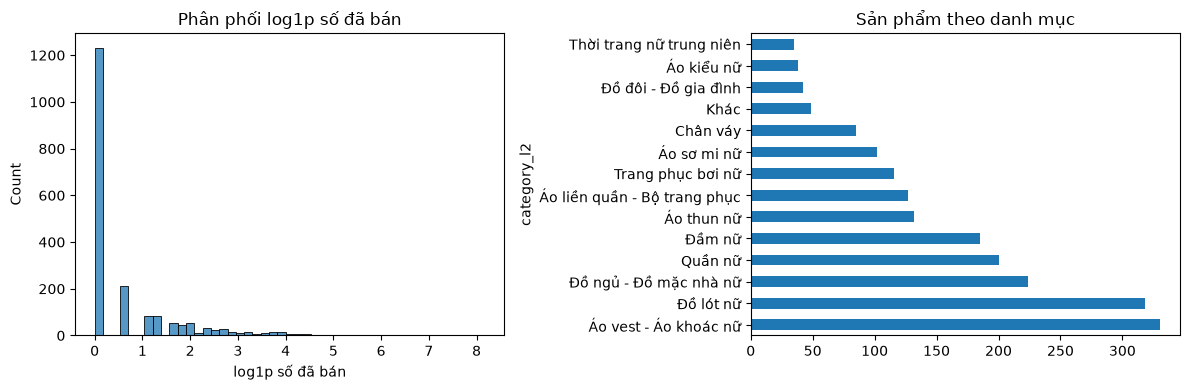

In [4]:
if not df.empty:
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    sns.histplot(np.log1p(pd.to_numeric(df.quantity_sold, errors='coerce').clip(lower=0)), ax=ax[0])
    ax[0].set(title='Phân phối log1p số đã bán', xlabel='log1p số đã bán')
    df.category_l2.value_counts().plot.barh(ax=ax[1], title='Sản phẩm theo danh mục')
    plt.tight_layout(); plt.show()
else: print('chưa có kết quả: dữ liệu đặc trưng')

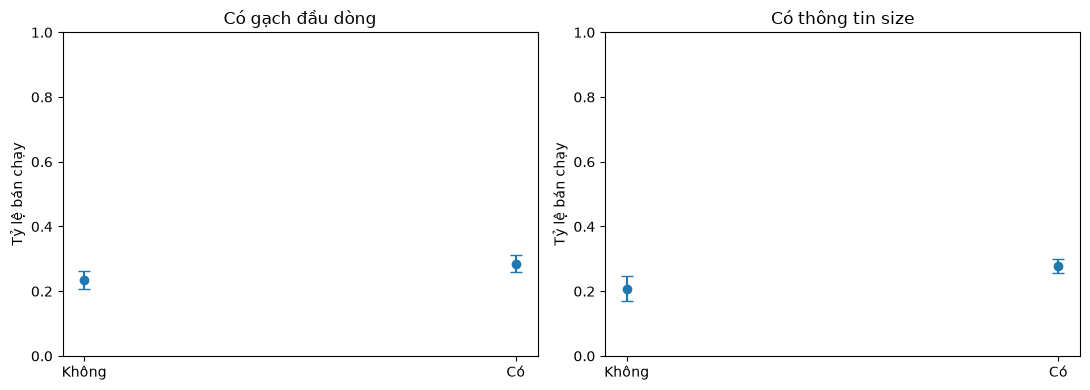

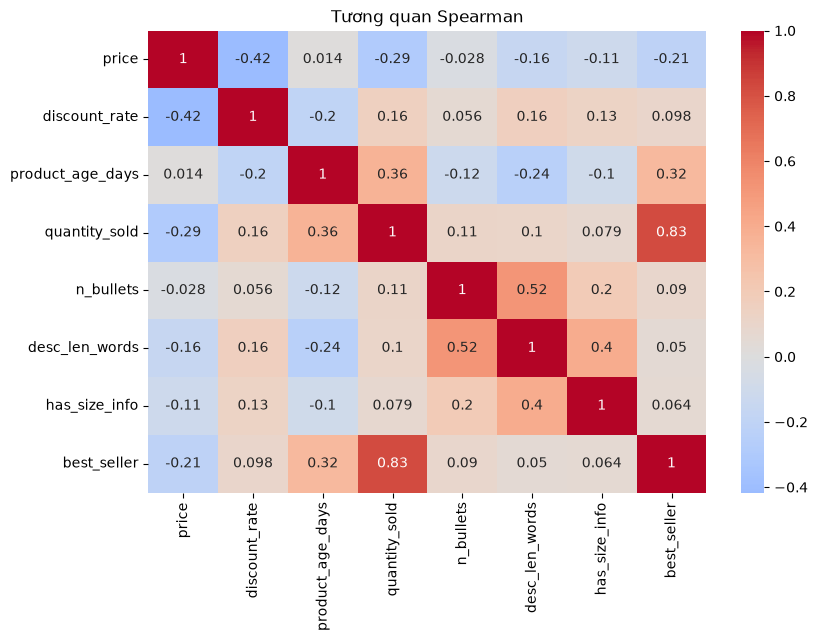

In [5]:
from statsmodels.stats.proportion import proportion_confint
if not df.empty:
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    for ax, col, label in zip(axes, ['n_bullets', 'has_size_info'], ['Có gạch đầu dòng', 'Có thông tin size']):
        group = df.assign(nhom=pd.to_numeric(df[col], errors='coerce').fillna(0).gt(0)).groupby('nhom').best_seller.agg(['sum', 'count'])
        p = group['sum'] / group['count']
        lo, hi = proportion_confint(group['sum'], group['count'], method='wilson')
        ax.errorbar(range(len(p)), p, yerr=[p-lo, hi-p], fmt='o', capsize=4)
        ax.set_xticks(range(len(p)), ['Có' if x else 'Không' for x in group.index]); ax.set(title=label, ylabel='Tỷ lệ bán chạy', ylim=(0, 1))
    plt.tight_layout(); plt.show()
    cols = ['price', 'discount_rate', 'product_age_days', 'quantity_sold', 'n_bullets', 'desc_len_words', 'has_size_info', 'best_seller']
    plt.figure(figsize=(9, 6)); sns.heatmap(df[cols].corr(method='spearman', numeric_only=True), annot=True, cmap='coolwarm', center=0); plt.title('Tương quan Spearman'); plt.show()

## 5. Phân tích mô tả
Các biến chính được tóm tắt theo phân phối và trung vị theo nhãn bán chạy.

In [6]:
if not df.empty:
    main_cols = ['price', 'discount_rate', 'quantity_sold', 'product_age_days', 'desc_len_words', 'n_bullets']
    display(df[main_cols].describe().T)
    display(df.groupby('best_seller')[main_cols].median())

,count,mean,std,min,25%,50%,75%,max
price,1983.0,393596.946546,547746.378255,3500.0,149000.0,226000.0,410000.0,5890000.0
discount_rate,1983.0,3.761977,9.197948,0.0,0.0,0.0,0.0,52.0
quantity_sold,1983.0,8.169945,89.657285,0.0,0.0,0.0,2.0,3546.0
product_age_days,1983.0,1386.971256,659.266034,12.0,768.0,1531.0,1947.0,2549.0
desc_len_words,1983.0,273.034291,149.195126,64.0,153.0,241.0,364.5,976.0
n_bullets,1983.0,4.794251,6.692920,0.0,0.0,2.0,7.0,36.0


,price,discount_rate,quantity_sold,product_age_days,desc_len_words,n_bullets
best_seller,,,,,,
0,249000.0,0.0,0.0,1313.5,238.0,1.0
1,189250.0,0.0,6.0,1828.0,247.0,3.0


## 6. Dự báo RQ1
Chia train/test phân tầng, chọn siêu tham số bằng CV trên train. Không đưa số đã bán, số đánh giá hoặc điểm đánh giá vào mô hình. Ablation giữ cùng thuật toán; chọn theo AUC CV, không chọn theo test.

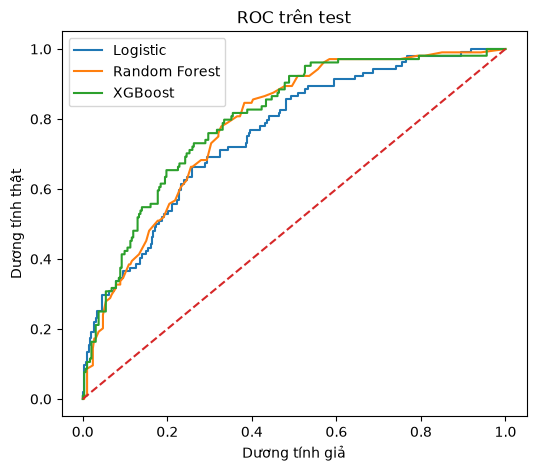

,Mô hình,AUC CV,ROC-AUC test,PR-AUC,F1
0,Logistic,0.809729,0.758762,0.550421,0.530466
1,Random Forest,0.810725,0.784179,0.521005,0.522523
2,XGBoost,0.817637,0.800456,0.572796,0.494382


In [7]:
from predictive import prepare, pipeline, CONTROL, CONTENT
# common.py chọn backend ghi ảnh; khôi phục backend inline để hiện biểu đồ notebook.
plt.switch_backend('module://matplotlib_inline.backend_inline')
from sklearn.model_selection import train_test_split, StratifiedKFold, RandomizedSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, average_precision_score, f1_score, roc_curve
from sklearn.inspection import permutation_importance
from xgboost import XGBClassifier
from scipy.stats import loguniform, randint
scores, fitted = [], {}
if not df.empty and df.best_seller.nunique() == 2 and df.best_seller.value_counts().min() >= 7:
    d = prepare(df); y = d.best_seller.astype(int)
    X = d[CONTROL + CONTENT + ['category_l2']]
    xt, xv, yt, yv = train_test_split(X, y, test_size=.2, stratify=y, random_state=42)
    cv = StratifiedKFold(n_splits=min(3, int(yt.value_counts().min())), shuffle=True, random_state=42)
    models = {
        'Logistic': (LogisticRegression(max_iter=1000, class_weight='balanced'), {'model__C': loguniform(.01, 10)}),
        'Random Forest': (RandomForestClassifier(class_weight='balanced', random_state=42, n_jobs=1), {'model__n_estimators': randint(30, 80), 'model__max_depth': [4, 8, None]}),
        'XGBoost': (XGBClassifier(n_jobs=1, random_state=42, eval_metric='logloss'), {'model__n_estimators': randint(30, 80), 'model__max_depth': randint(2, 5)})}
    fig, ax = plt.subplots(figsize=(6, 5))
    for name, (est, params) in models.items():
        search = RandomizedSearchCV(pipeline(est, CONTROL + CONTENT), params, n_iter=N_ITER, scoring='roc_auc', cv=cv, random_state=42, n_jobs=1)
        search.fit(xt, yt); fitted[name] = search
        prob = search.predict_proba(xv)[:, 1]
        scores.append({'Mô hình': name, 'AUC CV': search.best_score_, 'ROC-AUC test': roc_auc_score(yv, prob), 'PR-AUC': average_precision_score(yv, prob), 'F1': f1_score(yv, search.predict(xv), zero_division=0)})
        fpr, tpr, _ = roc_curve(yv, prob); ax.plot(fpr, tpr, label=name)
    ax.plot([0, 1], [0, 1], '--'); ax.set(xlabel='Dương tính giả', ylabel='Dương tính thật', title='ROC trên test'); ax.legend(); plt.show()
    display(pd.DataFrame(scores))
else: print('chưa có kết quả: không đủ dữ liệu hai lớp')

In [8]:
if fitted:
    best = max(fitted, key=lambda name: fitted[name].best_score_)
    est, params = models[best]
    control = RandomizedSearchCV(pipeline(est, CONTROL), params, n_iter=N_ITER, scoring='roc_auc', cv=cv, random_state=42, n_jobs=1).fit(xt, yt)
    display(pd.DataFrame([{'Mô hình chọn theo CV': best, 'Chỉ kiểm soát': roc_auc_score(yv, control.predict_proba(xv)[:, 1]), 'Thêm nội dung': roc_auc_score(yv, fitted[best].predict_proba(xv)[:, 1])}]))
    imp = permutation_importance(fitted[best], xv, yv, scoring='roc_auc', n_repeats=3, random_state=42, n_jobs=1)
    display(pd.DataFrame({'Biến': X.columns, 'Giảm AUC': imp.importances_mean}).sort_values('Giảm AUC', ascending=False).head(15))

,Mô hình chọn theo CV,Chỉ kiểm soát,Thêm nội dung
0,XGBoost,0.803951,0.800456


,Biến,Giảm AUC
2,product_age_days,0.129337
0,log_price,0.103084
24,category_l2,0.018438
9,n_paragraphs,0.013187
12,avg_sentence_len_words,0.012656
4,n_options,0.011223
6,title_len_words,0.010064
14,uppercase_ratio,0.010037
10,n_bullets,0.008078
5,title_len_chars,0.008007


In [9]:
# OR là liên hệ có kiểm soát, không phải hiệu ứng nhân quả.
if not df.empty:
    try:
        import statsmodels.api as sm
        from rq1_inference import build_design
        design = build_design(df)
        fit = sm.Logit(df.best_seller.astype(int), design).fit(disp=False, maxiter=200)
        ci = fit.conf_int()
        display(pd.DataFrame({'OR': np.exp(fit.params), 'CI thấp': np.exp(ci[0]), 'CI cao': np.exp(ci[1]), 'p': fit.pvalues}))
    except (ValueError, np.linalg.LinAlgError) as exc:
        print('chưa có kết quả Logit:', type(exc).__name__)

,OR,CI thấp,CI cao,p
const,0.035956,0.001483,0.871701,4.091638e-02
desc_len_words,0.966421,0.757519,1.232931,7.834168e-01
n_bullets,1.238325,1.061589,1.444485,6.515375e-03
n_paragraphs,1.122390,0.895328,1.407037,3.167270e-01
title_len_chars,1.308682,1.141565,1.500265,1.136748e-04
uppercase_ratio,1.018057,0.891309,1.162828,7.919338e-01
has_size_info,1.031168,0.730992,1.454609,8.612001e-01
has_material_info,1.455509,0.947926,2.234886,8.624599e-02
has_care_info,0.962932,0.704886,1.315446,8.124077e-01
has_cta,0.766248,0.544140,1.079017,1.273817e-01


## 7. Từ khóa đặc trưng
Thuật toán 1 tách cụm từ trong tên, loại từ chung và mã hàng, đếm tần suất theo sản phẩm, chọn cụm đủ phổ biến và cụ thể; tách train/test trước khi dùng trong sinh. Dữ liệu công khai chỉ chứa từ khóa tổng hợp.

In [10]:
if not IN_COLAB and 'name' in df.columns:
    from keywords import name_segments, candidate_phrases, select_keywords
    from collections import Counter
    phrases = [candidate_phrases(name_segments(r['name'], r.get('brand', ''), 'vi'), 'vi') for _, r in df.iterrows()]
    counts = Counter(p for group in phrases for p in group)
    chosen = [select_keywords(group, counts, len(df), 'vi') for group in phrases]
    keyword_result = {}
    for cat, indices in df.reset_index(drop=True).groupby('category_l2').groups.items():
        top = Counter(term for i in indices for term in chosen[i]).most_common(5)
        keyword_result[cat] = {'top_keywords': [{'keyword': term, 'count': count} for term, count in top]}
    print('Đã trích lại từ tên sản phẩm cục bộ.')
else:
    keyword_result = read_json(PUBLIC / 'keywords_by_category.json').get('tiki', {})
categories = keyword_result.get('categories', keyword_result)
keyword_rows = [{'Danh mục': cat, **item} for cat, obj in categories.items() if isinstance(obj, dict) for item in obj.get('top_keywords', [])[:5]]
display(pd.DataFrame(keyword_rows))

C:\Users\Minh\NgoaiKhoa_work\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Đã trích lại từ tên sản phẩm cục bộ.


,Danh mục,keyword,count
0,Chân váy,chân váy,61
1,Chân váy,chữ,10
2,Chân váy,xòe,8
3,Chân váy,ngắn,8
4,Chân váy,chân,7
...,...,...,...
65,Đồ đôi - Đồ gia đình,mr,27
66,Đồ đôi - Đồ gia đình,buffalo,25
67,Đồ đôi - Đồ gia đình,áo đôi,18
68,Đồ đôi - Đồ gia đình,lỡ,15


## 8. Phản đối của khách hàng
Bảng là số đếm theo chủ đề, không chứa nội dung review.

In [11]:
obj = read_json(ROOT / 'data/public/objection_themes_summary.json')
display(pd.DataFrame.from_dict(obj.get('by_category', {}), orient='index'))

,n_low_reviews,Size không vừa,Không giống hình/mô tả,Chất liệu kém,Màu sắc khác,"Đường may, lỗi sản phẩm","Giao hàng, đóng gói"
Chân váy,16,0,3,3,0,1,2
Quần nữ,26,3,2,2,0,4,1
Thời trang nữ trung niên,2,0,1,0,1,0,0
Trang phục bơi nữ,33,4,5,5,4,0,2
Áo kiểu nữ,6,1,0,3,0,1,0
Áo liền quần - Bộ trang phục,3,0,0,0,0,1,1
Áo sơ mi nữ,16,2,4,2,1,1,1
Áo thun nữ,4,1,1,0,0,0,2
Áo vest - Áo khoác nữ,56,1,18,7,2,1,5
Đầm nữ,19,0,4,1,0,1,1


## 9. Sinh nội dung
M1 zero-shot; M2 thêm ràng buộc; M3 thêm ví dụ truy hồi. Ví dụ minh họa dưới đây là dữ liệu giả lập; kết quả đã sinh được đọc riêng từ tệp công khai.

In [12]:
from prompts import zero_shot, engineered, fewshot_retrieval
brief = {'item_id': 'demo', 'category': 'Áo nữ', 'keywords': ['áo linen'], 'attributes': {'Chất liệu': 'linen'}, 'objections': []}
for name, prompt in [('M1', zero_shot([brief])), ('M2', engineered([brief])), ('M3', fewshot_retrieval([brief], {'demo': [{'brief': brief, 'description': 'Áo linen có phom dáng đơn giản.'}]}))]:
    print('\n', name, '\n', prompt)
if RUN_GENERATION:
    from llm_api import generate_via_api
    key = os.environ.get('GEMINI_API_KEY')
    if key:
        inputs = pd.read_csv(ROOT / 'data/public/gen_inputs_tiki_public.csv').head(2)
        for _, row in inputs.iterrows():
            b = {'item_id': str(row.product_id), 'category': row.category_l2, 'keywords': json.loads(row.keywords), 'attributes': json.loads(row.attributes)}
            print(generate_via_api(engineered([b]), 'gemini', key)[0])
    else: print('chưa có kết quả: thiếu GEMINI_API_KEY')


 M1 
 Bạn là người viết nội dung cho một cửa hàng thời trang nữ trên sàn thương mại điện tử.
Với mỗi sản phẩm trong brief, hãy viết: tiêu đề sản phẩm, đoạn mô tả meta, bài mô tả sản phẩm, kịch bản chốt sale (tin nhắn tư vấn gửi khách hàng) và 3 tiêu đề email marketing.
ĐỊNH DẠNG ĐẦU RA: chỉ trả về một mảng JSON hợp lệ, không giải thích, không markdown. Mỗi phần tử ứng với một sản phẩm và có đúng các khóa: item_id (giữ nguyên như brief), title, meta_description, description, sales_script, email_subjects (mảng gồm 3 chuỗi).

BRIEF:
[
 {
  "item_id": "demo",
  "category": "Áo nữ",
  "keywords": [
   "áo linen"
  ],
  "attributes": {
   "Chất liệu": "linen"
  },
  "objections": []
 }
]

 M2 
 Nhiệm vụ: viết nội dung bán hàng cho các sản phẩm thời trang nữ trong brief.
YÊU CẦU:
- VAI TRÒ: bạn là copywriter thương mại điện tử chuyên thời trang nữ, viết tiếng Việt tự nhiên, đúng chính tả.
- TỪ KHÓA CHÍNH: là từ khóa đầu tiên trong danh sách keywords của từng sản phẩm.
- DỮ KIỆN: chỉ dùng thô

In [13]:
def show_generations(methods):
    for method in methods:
        paths = sorted((PUBLIC / 'generations').glob('generations_' + method + '_*.jsonl'))
        if not paths:
            print(method, ': chưa có kết quả'); continue
        path = next((p for p in paths if p.name.endswith('_tiki.jsonl')), paths[0])
        with open(path, encoding='utf-8-sig') as f:
            records = [json.loads(line) for line in f if line.strip()][:2]
        print(method, '—', path.name)
        for record in records: display(record.get('output', {}))
show_generations(['M0', 'M1', 'M2', 'M3'])

M0 — generations_M0_tiki.jsonl


{'title': 'áo ngực áo bra dây - Đồ lót nữ',
 'meta_description': 'áo ngực - Đồ lót nữ. áo bra, dây, trễ vai.',
 'description': 'Áo ngực thuộc danh mục Đồ lót nữ.\nĐặc điểm nổi bật: áo ngực, áo bra, dây, trễ vai, tính, áo trễ.\nThông tin sản phẩm: Xuất xứ: China / Vietnam.\nSản phẩm phù hợp nhiều dịp sử dụng hằng ngày.\nVui lòng liên hệ cửa hàng để được tư vấn chọn size.',
 'sales_script': 'Chào chị, mẫu áo ngực bên em hiện vẫn còn hàng ạ. Chị cho em xin chiều cao và cân nặng để em tư vấn size phù hợp nhé. Chị đặt hàng ngay để nhận sản phẩm sớm ạ!',
 'email_subjects': ['áo ngực - mẫu mới',
  'Khám phá áo ngực',
  'Đồ lót nữ: gợi ý cho bạn']}

{'title': 'áo khoát dễ thương jean - Áo vest - Áo khoác nữ',
 'meta_description': 'áo khoát - Áo vest - Áo khoác nữ. dễ thương, jean.',
 'description': 'Áo khoát thuộc danh mục Áo vest - Áo khoác nữ.\nĐặc điểm nổi bật: áo khoát, dễ thương, jean.\nThông tin sản phẩm: Xuất xứ: Việt Nam; Màu sắc: Xanh nhạt, Xanh đậm; Kích cỡ: L(55-64kg), M(45-54kg), XL(65-74kg).\nSản phẩm phù hợp nhiều dịp sử dụng hằng ngày.\nVui lòng liên hệ cửa hàng để được tư vấn chọn size.',
 'sales_script': 'Chào chị, mẫu áo khoát bên em hiện vẫn còn hàng ạ. Chị cho em xin chiều cao và cân nặng để em tư vấn size phù hợp nhé. Chị đặt hàng ngay để nhận sản phẩm sớm ạ!',
 'email_subjects': ['áo khoát - mẫu mới',
  'Khám phá áo khoát',
  'Áo vest - Áo khoác nữ: gợi ý cho bạn']}

M1 — generations_M1_tiki.jsonl


{'title': 'Áo bra nữ có dây phối áo trễ vai',
 'meta_description': 'Áo bra nữ có dây, gợi ý phối cùng áo trễ vai. Liên hệ shop để xem ảnh, tư vấn kiểu dáng, kích cỡ và thông tin giao hàng.',
 'description': 'Áo bra nữ có dây là lựa chọn để bạn tham khảo khi phối cùng trang phục trễ vai. Xuất xứ theo thông tin sản phẩm: Trung Quốc hoặc Việt Nam. Trước khi đặt hàng, bạn hãy nhắn shop để được gửi ảnh sản phẩm, xác nhận xuất xứ và tư vấn kích cỡ phù hợp.',
 'sales_script': 'Dạ, chị đang tìm áo bra mặc cùng áo trễ vai phải không ạ? Shop có thể gửi chị ảnh sản phẩm và tư vấn kiểu dây, kích cỡ trước khi đặt. Chị cho shop xin số đo vòng ngực và khu vực nhận hàng để shop kiểm tra thông tin sản phẩm, cách đóng gói và thời gian giao dự kiến nhé.',
 'email_subjects': ['Áo bra có dây cho những set đồ trễ vai',
  'Tìm áo bra phối cùng áo trễ vai? Xem ngay',
  'Nhắn shop chọn áo bra phù hợp với bạn']}

{'title': 'Áo khoác jean nữ dễ thương màu xanh nhạt, xanh đậm',
 'meta_description': 'Áo khoác jean nữ xuất xứ Việt Nam, có hai màu xanh nhạt và xanh đậm, size M đến XL. Nhắn shop xem ảnh và tư vấn size.',
 'description': 'Áo khoác jean nữ mang đến gợi ý phối đồ dễ thương cho những ngày đi học, đi chơi hoặc dạo phố.\n\nSản phẩm có hai màu xanh nhạt và xanh đậm, xuất xứ Việt Nam. Size tham khảo theo cân nặng: M 45–54 kg, L 55–64 kg, XL 65–74 kg. Để chọn size phù hợp hơn, bạn hãy gửi chiều cao và số đo cho shop. Shop cũng có thể cung cấp thêm ảnh và thông tin về chất liệu trước khi bạn đặt hàng.',
 'sales_script': 'Dạ, mẫu áo khoác jean này có màu xanh nhạt và xanh đậm, size M, L, XL chị nhé. Chị cho shop xin chiều cao, cân nặng và số đo để tư vấn size phù hợp ạ. Nếu chị muốn xem kỹ màu áo và chất liệu, shop sẽ gửi thêm thông tin, hình ảnh để chị tham khảo trước khi đặt.',
 'email_subjects': ['Áo khoác jean dễ thương cho ngày xuống phố',
  'Xanh nhạt hay xanh đậm: bạn chọn màu nào?',
  '

... (2 outputs left out)

{'title': 'cardigan sweater: Floral Knit Style with Buttons',
 'meta_description': 'Discover a cardigan sweater with floral and knit details and buttons, made for a distinctive look. View the product.',
 'description': 'The cardigan sweater brings floral detail, a knit look and buttons together in a style designed for women.\n\nA cardigan can be a useful starting point when you want to put together an outfit around a piece with visual detail. Here, the floral element adds interest, while the knit style gives the design its character. The buttons are another feature to notice as you explore the look.\n\nWhether you are choosing something to pair with pieces already in your wardrobe or looking for a cardigan with a floral touch, this style offers a combination of details to consider. You can let the floral design stand out or keep the rest of your outfit simple so the cardigan remains the focus.\n\n• Style: Floral knit cardigan with buttons.\n• Department: Women’s.\n\nThink about the loo

M3 — generations_M3_amazon.jsonl


{'title': 'dress summer Green Flowy Maxi with Spaghetti Straps',
 'meta_description': 'Discover a dress summer look in green, with a flowy maxi silhouette and spaghetti straps for vacation styling. View the product.',
 'description': 'The dress summer look brings together a green color, spaghetti straps and a flowy maxi silhouette for women. It is an option to consider when you want a dress for a vacation wardrobe and prefer a long, flowing look.\n\nThe maxi style gives you a direction for putting an outfit together. Let the green color lead your choices, or use the dress as the starting point for a look that feels like your own. The spaghetti straps add another element to the overall style, while the flowy silhouette keeps the emphasis on movement and shape.\n\nFor vacation planning, think about how you like to dress and what you want your outfit to express. This dress can be considered as a complete starting point, with its color and silhouette providing the main visual elements. Cho

{'title': 'cardigan sweater Floral Knit with Button Detail',
 'meta_description': 'Explore a cardigan sweater for women with a floral knit look and button detail, ready to add to your wardrobe. View the product.',
 'description': 'This cardigan sweater for women brings floral, knit and button details together in one wardrobe piece. If you are looking for a sweater with a floral element and the familiar cardigan style, it offers a place to start.\n\nThe floral detail gives you a point of interest to consider as you plan an outfit. The knit construction and button detail add to the cardigan look, making it a piece you can coordinate with items you already enjoy wearing. Think about the colors and combinations you reach for when deciding how you would style it.\n\nA cardigan can become part of many personal outfit ideas. You might choose to make the floral element the focus or bring it into a look alongside other pieces from your wardrobe. The choice is yours: start with the detail that a

## 10. Tinh chỉnh LoRA
Mặc định dùng tập Amazon đã tiền xử lý và GPU; quá trình có thể tải mô hình và cần thời gian. Khi chưa chạy, xem log và đầu ra đã lưu.

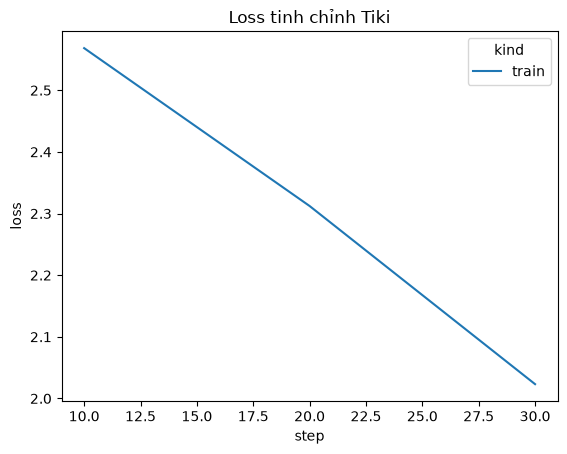

M4a : chưa có kết quả
M4b : chưa có kết quả


In [14]:
import torch
if RUN_FINETUNE and torch.cuda.is_available():
    subprocess.run([sys.executable, 'src/finetune_lora.py', '--dataset', 'amazon', '--train', '--generate'], check=True)
elif RUN_FINETUNE: print('chưa có kết quả: cần GPU')
loss_path = PUBLIC / 'finetune_tiki.csv'
if loss_path.exists():
    loss = pd.read_csv(loss_path)
    if not loss.empty:
        sns.lineplot(data=loss, x='step', y='loss', hue='kind'); plt.title('Loss tinh chỉnh Tiki'); plt.show()
else: print('chưa có kết quả: loss')
show_generations(['M4a', 'M4b'])

## 11. Đánh giá
ROUGE-L, chrF++ và BERTScore so với tham chiếu; checklist và tỷ lệ thuộc tính không có căn cứ là thước đo theo luật, không thay thế kiểm duyệt. Các ngưỡng S../E.. ánh xạ trong `src/evaluate.py` và `_workspace/01_research/verified_refs.md`; proxy được ghi rõ trong mã. Wilcoxon đã hiệu chỉnh Holm lấy từ kết quả lưu.

In [15]:
if RUN_JUDGE:
    print('Để chấm lại, chạy src/evaluate.py với dữ liệu đầu vào và backend phù hợp; cần API.')
eval_files = sorted(PUBLIC.glob('eval_per_item_*.csv'))
summary_files = sorted(PUBLIC.glob('eval_summary_*.json'))
evaluation = pd.concat([pd.read_csv(p).assign(nguon=p.name) for p in eval_files], ignore_index=True) if eval_files else pd.DataFrame()
if evaluation.empty: print('chưa có kết quả: đánh giá theo sản phẩm')
else:
    metrics = [c for c in ['rougeL', 'chrf_plus_plus', 'bertscore_f1', 'seo_compliance_rate', 'hallucination_rate', 'latency_s'] if c in evaluation]
    metrics += [c for c in evaluation if c.startswith(('email_', 'judge_')) and pd.api.types.is_numeric_dtype(evaluation[c])]
    comparison = evaluation.groupby('method')[metrics].mean(numeric_only=True)
    display(comparison)
    if 'rougeL' in comparison:
        comparison['rougeL'].plot.bar(title='ROUGE-L trung bình'); plt.ylabel('ROUGE-L'); plt.show()
for path in summary_files:
    result = read_json(path)
    print(path.name, '— Wilcoxon/Holm'); display(pd.DataFrame(result.get('wilcoxon_holm', [])))
if not summary_files: print('chưa có kết quả: Wilcoxon')
from evaluate import SEO_LABELS, EMAIL_LABELS
display(pd.DataFrame([{'Loại': kind, 'Tiêu chí': k, 'Nguồn': v} for kind, labels in [('SEO', SEO_LABELS), ('Email', EMAIL_LABELS)] for k, v in labels.items()]))

chưa có kết quả: đánh giá theo sản phẩm
chưa có kết quả: Wilcoxon


,Loại,Tiêu chí,Nguồn
0,SEO,title_len_50_60,S19
1,SEO,title_tiki_15_50,S23
2,SEO,title_tiki_max_225,S23
3,SEO,meta_len_120_156,S12
4,SEO,keyphrase_in_title,S11
5,SEO,keyphrase_in_first_paragraph,S10
6,SEO,keyphrase_in_meta,S11
7,SEO,density_proxy_0_5_3,S09 proxy
8,SEO,desc_words_ge_200,S13/S24
9,Email,mailchimp_le9w_le60c,E01


## 12. Phân tích đề xuất
Chọn cấu hình theo từng chỉ số thực đo. Độ trễ nhân 100 là ước tính tuần tự, không bao gồm kiểm duyệt; các chỉ số thiếu không được suy diễn.

In [16]:
if not evaluation.empty:
    for metric, higher in [('rougeL', True), ('chrf_plus_plus', True), ('bertscore_f1', True), ('seo_compliance_rate', True), ('hallucination_rate', False), ('latency_s', False)]:
        if metric in comparison and comparison[metric].notna().any():
            s = comparison[metric].dropna(); method = s.idxmax() if higher else s.idxmin()
            print(metric, ':', method, '=', s.loc[method])
    if 'latency_s' in comparison: display((comparison['latency_s'] * 100).rename('Giây cho 100 sản phẩm, tuần tự'))
else: print('chưa có kết quả: chưa thể chọn cấu hình')
print('Quy trình: kiểm tra brief → sinh → người duyệt dữ kiện, giọng điệu và chính sách → chỉnh sửa → đăng.')

chưa có kết quả: chưa thể chọn cấu hình
Quy trình: kiểm tra brief → sinh → người duyệt dữ kiện, giọng điệu và chính sách → chỉnh sửa → đăng.


## 13. Công cụ AI được sử dụng
| Công cụ | Vai trò được khai báo |
|---|---|
| Claude Opus 5.5 qua Claude Code | Điều phối, viết bài, kiểm chứng |
| GPT-6.1-Terra / GPT-6.1-Sol qua Codex CLI | Viết code, tra cứu, sinh nội dung M1–M3 |
| Gemini 3.8 Flash qua Antigravity CLI | Giám khảo LLM |
| Qwen2.5-0.5B-Instruct | Mô hình tinh chỉnh LoRA |
| bert-base-multilingual-cased | BERTScore |

Tên và vai trò do nhóm nghiên cứu cung cấp; đối chiếu nhật ký trước khi công bố.

## 14. Tài liệu tham khảo chính
- Hou, Y., et al. (2024). *Bridging language and items for retrieval and recommendation*. Amazon Reviews 2023.
- Google. *Search Central: Creating helpful, reliable, people-first content*. https://developers.google.com/search/docs/fundamentals/creating-helpful-content
- Hu, E. J., et al. (2022). *LoRA: Low-rank adaptation of large language models*. https://arxiv.org/abs/2106.09685
- Zhang, T., et al. (2020). *BERTScore: Evaluating text generation with BERT*. https://arxiv.org/abs/1904.09675
- Nguồn chi tiết các tiêu chí: `_workspace/01_research/verified_refs.md`.